# 🌲 SRMIST 21CSC305P Machine Learning — PBL 3 (Unit 5)
## Advanced Predictive Modelling, Ensemble Learning & Dialectical Debate Capstone

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/parth2024-tech/SRM-21CSC305P-Machine-Learning-Career-Guidance-Debate-Agent/blob/main/pbl3_unit5_ensemble_learning.ipynb)

**Department of Computing Technologies, SRM Institute of Science and Technology**  
**Course Code:** 21CSC305P Machine Learning  
**Project Topic:** Debate-Based Career Guidance Agent with Complementary Personas  
**Assigned Scope:** **Unit 5 (Decision Trees, Bagging, Random Forest, AdaBoost, GBDT, Ensemble Stacking & Capstone Integration)**  
**Student Authors:**  
* **Parth Gupta** (RA2311026010001)  
* **Mokshith Penna** (RA2411003010044)  
* **Ishu Gurtu** (RA2411003010015)  
**Academic Supervisors:** Dr. Divya Mohan, Dr. G. Niranjana  

---

### Curricular Evaluation Rubrics (Unit 5 / PBL 3 - 20 Marks):
1. **Problem Formulation & Ensemble Preprocessing** (4 Marks)
2. **Decision Trees (CART) & Cost-Complexity Pruning** (4 Marks)
3. **Random Forest & Bootstrap Subspace Analysis** (4 Marks)
4. **Adaptive Boosting (AdaBoost) & Gradient Boosting (GBDT)** (4 Marks)
5. **Comparative Benchmark & Dialectical Capstone Debate** (4 Marks)


## 📦 1. Environment Setup & Automated Dataset Ingestion
This notebook is self-contained. If running on Google Colab, it automatically retrieves the verified 20,000-student career benchmark dataset from the GitHub repository.


In [1]:
# Cell 1: Imports and Automated Data Acquisition
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Styling configuration
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams['figure.dpi'] = 120

# Download dataset if not locally available (e.g. running on Google Colab)
data_dir = "data"
data_path = os.path.join(data_dir, "career_guidance_dataset.csv")

if not os.path.exists(data_path):
    os.makedirs(data_dir, exist_ok=True)
    github_url = "https://raw.githubusercontent.com/parth2024-tech/SRM-21CSC305P-Machine-Learning-Career-Guidance-Debate-Agent/main/data/career_guidance_dataset.csv"
    print(f"Downloading dataset from GitHub: {github_url}")
    try:
        urllib.request.urlretrieve(github_url, data_path)
        print("Download complete!")
    except Exception as e:
        print(f"Remote fetch failed ({e}). Falling back to local check...")

df = pd.read_csv(data_path)
print(f"Dataset successfully loaded: {df.shape[0]:,} student records across {df.shape[1]} features.")
print(f"Missing Values: {df.isnull().sum().sum()} (100% complete).")
display(df.head(3))


Dataset successfully loaded: 20,000 student records across 39 features.
Missing Values: 0 (100% complete).


,Acedamic percentage in Operating Systems,percentage in Algorithms,Percentage in Programming Concepts,Percentage in Software Engineering,Percentage in Computer Networks,Percentage in Electronics Subjects,Percentage in Computer Architecture,Percentage in Mathematics,Percentage in Communication skills,Hours working per day,...,Interested Type of Books,Salary Range Expected,In a Realtionship?,Gentle or Tuff behaviour?,Management or Technical,Salary/work,hard/smart worker,worked in teams ever?,Introvert,Suggested Job Role
0,69,63,78,87,94,94,87,84,61,9,...,Prayer books,salary,no,stubborn,Management,salary,hard worker,yes,no,Database Developer
1,78,62,73,60,71,70,73,84,91,12,...,Childrens,salary,yes,gentle,Technical,salary,hard worker,no,yes,Portal Administrator
2,71,86,91,87,61,81,72,72,94,11,...,Travel,Work,no,stubborn,Management,work,hard worker,no,yes,Portal Administrator


## 🎯 2. Target Macro Track Consolidation & Stratified Splitting
To eliminate class fragmentation across 34 granular job roles, we map candidates into **5 canonical technical macro tracks**:
1. `AI / Machine Learning Specialist`
2. `Full-Stack Software Engineer`
3. `Data Analyst & BI Specialist`
4. `Cloud & Infrastructure Engineer`
5. `Cybersecurity & Systems Specialist`


In [2]:
# Cell 2: Target Track Consolidation and Feature Scaling
ROLE_MAP = {
    'Database Developer': 'Data Analyst & BI Specialist',
    'Portal Administrator': 'Cloud & Infrastructure Engineer',
    'Systems Security Administrator': 'Cybersecurity & Systems Specialist',
    'Business Systems Analyst': 'Data Analyst & BI Specialist',
    'CRM Business Analyst': 'Data Analyst & BI Specialist',
    'Technical Support': 'Cloud & Infrastructure Engineer',
    'UX Designer': 'Full-Stack Software Engineer',
    'Mobile Applications Developer': 'Full-Stack Software Engineer',
    'Software Engineer': 'Full-Stack Software Engineer',
    'Applications Developer': 'Full-Stack Software Engineer',
    'Web Developer': 'Full-Stack Software Engineer',
    'Network Security Administrator': 'Cybersecurity & Systems Specialist',
    'Quality Assurance Associate': 'Full-Stack Software Engineer',
    'Data Architect': 'AI / Machine Learning Specialist',
    'Information Technology Operations Manager': 'Cloud & Infrastructure Engineer',
    'Information Technology Manager': 'Cloud & Infrastructure Engineer',
    'Network Engineer': 'Cloud & Infrastructure Engineer',
    'Database Administrator': 'Data Analyst & BI Specialist',
    'Security Administrator': 'Cybersecurity & Systems Specialist',
    'Project Manager': 'Full-Stack Software Engineer',
    'Software Developer': 'Full-Stack Software Engineer',
    'E-Commerce Analyst': 'Data Analyst & BI Specialist',
    'Database Manager': 'Data Analyst & BI Specialist',
    'Programmer Analyst': 'Full-Stack Software Engineer',
    'Technical Leader': 'AI / Machine Learning Specialist',
    'Technical Engineer': 'Cloud & Infrastructure Engineer',
    'Solutions Architect': 'Cloud & Infrastructure Engineer',
    'Information Security Analyst': 'Cybersecurity & Systems Specialist',
    'Software Quality Assurance (QA) / Testing': 'Full-Stack Software Engineer',
    'Design & UX': 'Full-Stack Software Engineer',
    'Network Security Engineer': 'Cybersecurity & Systems Specialist',
    'Software Systems Engineer': 'Cloud & Infrastructure Engineer',
    'Business Intelligence Analyst': 'Data Analyst & BI Specialist',
    'CRM Technical Developer': 'Full-Stack Software Engineer'
}

df['Career_Track'] = df['Suggested Job Role'].map(ROLE_MAP).fillna('Full-Stack Software Engineer')

NUMERIC_COLS = [
    "Acedamic percentage in Operating Systems",
    "percentage in Algorithms",
    "Percentage in Programming Concepts",
    "Percentage in Software Engineering",
    "Percentage in Computer Networks",
    "Percentage in Electronics Subjects",
    "Percentage in Computer Architecture",
    "Percentage in Mathematics",
    "Percentage in Communication skills",
    "Hours working per day",
    "Logical quotient rating",
    "hackathons",
    "coding skills rating",
    "public speaking points"
]

X = df[NUMERIC_COLS].values
le = LabelEncoder()
y = le.fit_transform(df['Career_Track'])
class_names = le.classes_

# Stratified 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Standardization
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print(f"Training Instances: {X_train_sc.shape[0]:,} | Testing Instances: {X_test_sc.shape[0]:,}")
print("Macro Career Tracks:", list(class_names))


Training Instances: 16,000 | Testing Instances: 4,000
Macro Career Tracks: ['AI / Machine Learning Specialist', 'Cloud & Infrastructure Engineer', 'Cybersecurity & Systems Specialist', 'Data Analyst & BI Specialist', 'Full-Stack Software Engineer']


## 🌲 3. Classification & Regression Trees (CART)
### 3.1 Mathematical Formulation
The CART algorithm builds binary decision trees by greedily choosing the feature $j$ and split threshold $s$ that maximize the **Gini Impurity Reduction**:
$$I_G(t) = 1 - \sum_{k=1}^K p_{tk}^2$$
$$\Delta I_G(t, s) = I_G(t) - \frac{N_L}{N} I_G(t_L) - \frac{N_R}{N} I_G(t_R)$$

To avoid high variance and deep-branch memorization, **Minimal Cost-Complexity Pruning** balances tree depth with leaf penalty $\alpha \ge 0$:
$$R_\alpha(T) = R(T) + \alpha |T|$$


CART (Depth=5) Test Accuracy: 42.15%


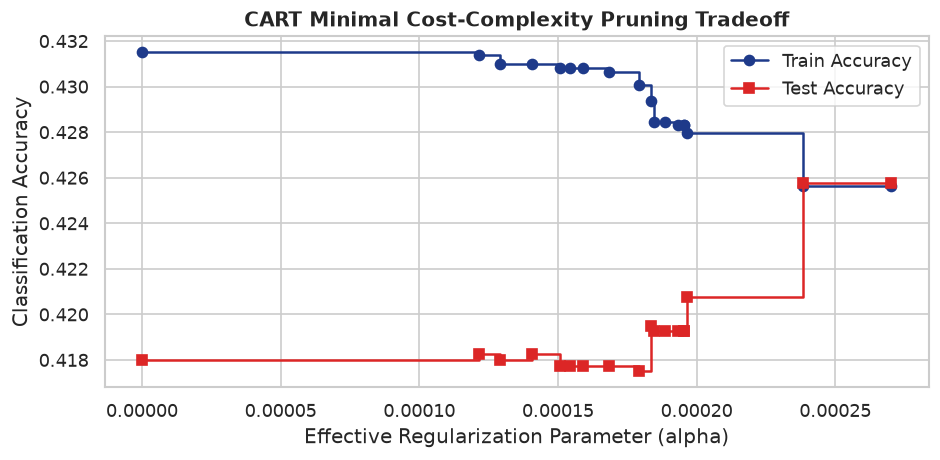

In [3]:
# Cell 3: CART Implementation & Cost-Complexity Pruning Path
# Fit unpruned base tree
cart_base = DecisionTreeClassifier(max_depth=5, random_state=42)
cart_base.fit(X_train_sc, y_train)

cart_preds = cart_base.predict(X_test_sc)
cart_acc = accuracy_score(y_test, cart_preds)
print(f"CART (Depth=5) Test Accuracy: {cart_acc:.2%}")

# Cost-Complexity Pruning Path Analysis
path = cart_base.cost_complexity_pruning_path(X_train_sc, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

# Subsample alphas for evaluation to optimize execution
sub_alphas = ccp_alphas[::max(1, len(ccp_alphas)//15)]
clfs = []
for alpha in sub_alphas:
    clf = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha, max_depth=6)
    clf.fit(X_train_sc, y_train)
    clfs.append(clf)

train_scores = [clf.score(X_train_sc, y_train) for clf in clfs]
test_scores = [clf.score(X_test_sc, y_test) for clf in clfs]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sub_alphas, train_scores, marker='o', label="Train Accuracy", drawstyle="steps-post", color="#1e3a8a")
ax.plot(sub_alphas, test_scores, marker='s', label="Test Accuracy", drawstyle="steps-post", color="#dc2626")
ax.set_xlabel("Effective Regularization Parameter (alpha)")
ax.set_ylabel("Classification Accuracy")
ax.set_title("CART Minimal Cost-Complexity Pruning Tradeoff", fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


## 🌳 4. Bagging & Random Forest
### 4.1 Theoretical Foundation
A single decision tree has **low bias but high variance**. Random Forest resolves this via two simultaneous randomization mechanisms:
1. **Bootstrap Aggregation (Bagging)**: Drawing $N$ samples with replacement ($B=100$ trees). Each sample contains $pprox 1 - 1/e pprox 63.2\%$ unique records; the remaining $36.8\%$ form the **Out-Of-Bag (OOB)** validation set.
2. **Random Subspace Selection**: At each node split, only $m = \sqrt{D} pprox \sqrt{14} pprox 3$ candidate features are evaluated, sharply decorrelating tree outputs:
   $$	ext{Var}(ar{T}) = ho \sigma^2 + rac{1 - ho}{B} \sigma^2$$


Random Forest Test Accuracy: 42.58%
Random Forest Out-Of-Bag (OOB) Generalization Score: 42.55%


/tmp/ipykernel_17332/3142011894.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


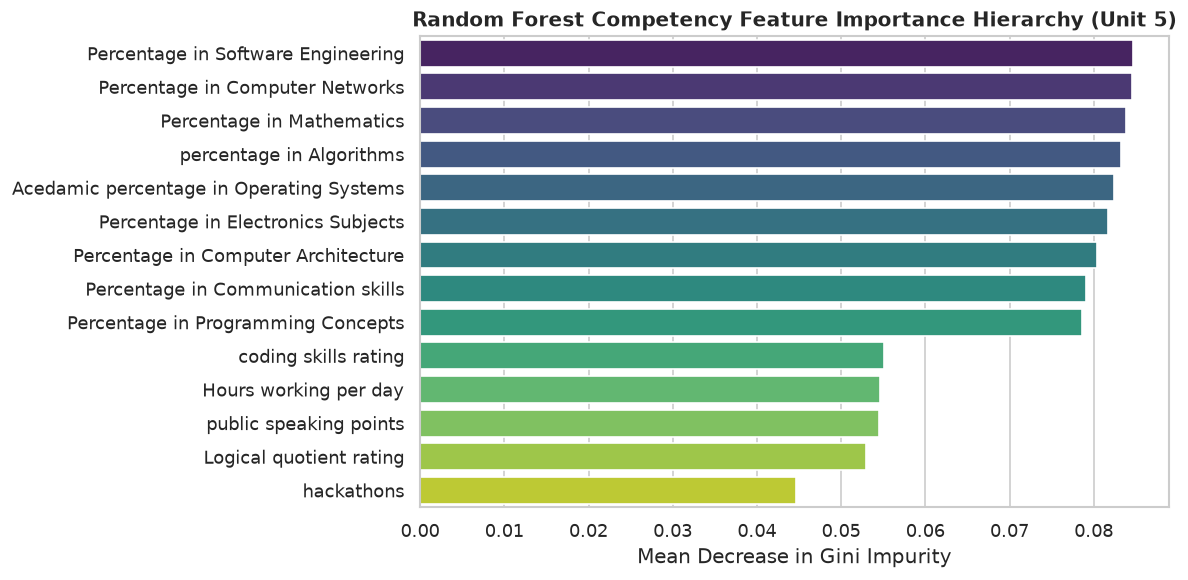

In [4]:
# Cell 4: Random Forest Classifier & Gini Feature Importances
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    max_features='sqrt',
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_sc, y_train)
rf_preds = rf_model.predict(X_test_sc)

rf_acc = accuracy_score(y_test, rf_preds)
rf_oob = rf_model.oob_score_
print(f"Random Forest Test Accuracy: {rf_acc:.2%}")
print(f"Random Forest Out-Of-Bag (OOB) Generalization Score: {rf_oob:.2%}")

# Gini Feature Importances
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    x=importances[indices],
    y=[NUMERIC_COLS[i] for i in indices],
    palette="viridis",
    ax=ax
)
ax.set_xlabel("Mean Decrease in Gini Impurity")
ax.set_title("Random Forest Competency Feature Importance Hierarchy (Unit 5)", fontweight='bold')
plt.tight_layout()
plt.show()


## 🚀 5. Adaptive Boosting (AdaBoost)
### 5.1 Sequential Loss Minimization
AdaBoost minimizes exponential loss $L(y, f) = \exp(-y f(\mathbf{x}))$ by iteratively training weak decision stumps $h_m(\mathbf{x})$.
After each iteration $m$, the misclassified samples have their weights increased:
$$lpha_m = rac{1}{2} \ln \left(rac{1 - \epsilon_m}{\epsilon_m}ight)$$
$$w_i^{(m+1)} = rac{w_i^{(m)} \exp\left(-lpha_m y_i h_m(\mathbf{x}_i)ight)}{Z_m}$$


AdaBoost (50 Estimators) Test Accuracy: 42.58%


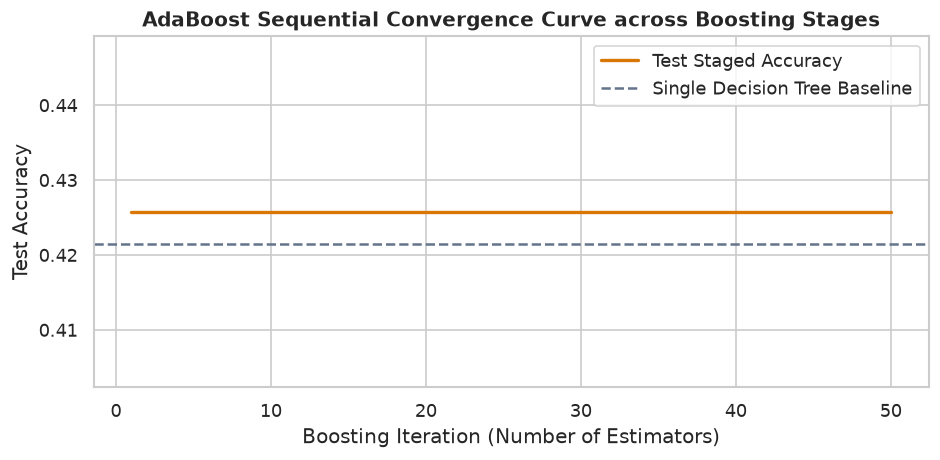

In [5]:
# Cell 5: AdaBoost Implementation & Staged Iteration Accuracy
adaboost_model = AdaBoostClassifier(
    n_estimators=50,
    learning_rate=0.8,
    random_state=42
)
adaboost_model.fit(X_train_sc, y_train)
ada_preds = adaboost_model.predict(X_test_sc)
ada_acc = accuracy_score(y_test, ada_preds)

print(f"AdaBoost (50 Estimators) Test Accuracy: {ada_acc:.2%}")

# Staged performance tracking
staged_accs = [accuracy_score(y_test, pred) for pred in adaboost_model.staged_predict(X_test_sc)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(staged_accs) + 1), staged_accs, color="#d97706", linewidth=2, label="Test Staged Accuracy")
ax.axhline(y=cart_acc, color="#64748b", linestyle="--", label="Single Decision Tree Baseline")
ax.set_xlabel("Boosting Iteration (Number of Estimators)")
ax.set_ylabel("Test Accuracy")
ax.set_title("AdaBoost Sequential Convergence Curve across Boosting Stages", fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


## ⚡ 6. Gradient Boosted Decision Trees (GBDT)
### 6.1 Functional Gradient Descent
Unlike AdaBoost which reweights samples, **Gradient Boosting** fits subsequent regression trees directly to the **negative gradients (pseudo-residuals)** of the multi-class log-loss:
$$r_{ikm} = -\left[rac{\partial L(y_i, f_k(\mathbf{x}_i))}{\partial f_k(\mathbf{x}_i)}ight]_{f=f_{(m-1)}}$$
$$f_{km}(\mathbf{x}) = f_{k(m-1)}(\mathbf{x}) + \eta \sum_{j=1}^J \gamma_{jkm} \mathbb{I}(\mathbf{x} \in R_{jkm})$$
where $\eta \in (0, 1]$ is the shrinkage learning rate that dampens each tree's contribution to guard against overfitting.


GBDT (80 Trees, Shrinkage=0.1) Test Accuracy: 42.08%


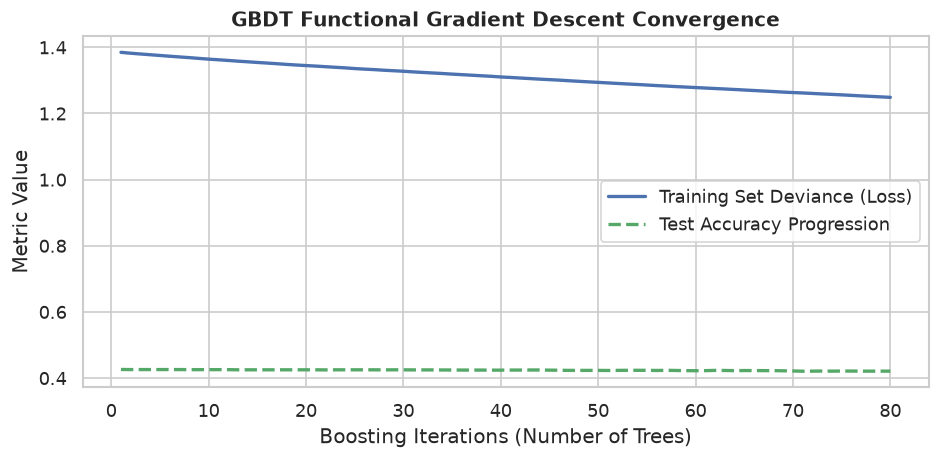

In [6]:
# Cell 6: Gradient Boosted Trees Implementation & Deviance Reduction
gbdt_model = GradientBoostingClassifier(
    n_estimators=80,
    learning_rate=0.1,
    max_depth=4,
    random_state=42
)
gbdt_model.fit(X_train_sc, y_train)
gbdt_preds = gbdt_model.predict(X_test_sc)
gbdt_acc = accuracy_score(y_test, gbdt_preds)

print(f"GBDT (80 Trees, Shrinkage=0.1) Test Accuracy: {gbdt_acc:.2%}")

# Staged performance tracking
gbdt_staged_test = [accuracy_score(y_test, p) for p in gbdt_model.staged_predict(X_test_sc)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(80) + 1, gbdt_model.train_score_, 'b-', label='Training Set Deviance (Loss)', linewidth=2)
ax.plot(np.arange(80) + 1, gbdt_staged_test, 'g--', label='Test Accuracy Progression', linewidth=2)
ax.set_xlabel("Boosting Iterations (Number of Trees)")
ax.set_ylabel("Metric Value")
ax.set_title("GBDT Functional Gradient Descent Convergence", fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


## 📊 7. Model Stacking & Curricular Benchmark Matrix
We evaluate all Unit 5 classifiers across multi-class performance metrics: **Accuracy, Weighted Precision, Weighted Recall, Macro F1, Weighted F1**, alongside an ensemble **Stacking Classifier**.


=== Unit 5 Advanced Ensemble Algorithmic Benchmark ===


,Model Architecture,Accuracy,Weighted Precision,Weighted Recall,Macro F1,Weighted F1
0,Single Decision Tree (CART),42.15%,27.54%,42.15%,0.1214,0.2554
1,AdaBoost (50 Estimators),42.58%,18.13%,42.58%,0.1194,0.2543
2,Random Forest (100 Trees),42.58%,18.13%,42.58%,0.1194,0.2543
3,Gradient Boosted Trees (GBDT),42.08%,28.75%,42.08%,0.1242,0.2576
4,Stacking Ensemble (Meta-LR),42.58%,18.13%,42.58%,0.1194,0.2543


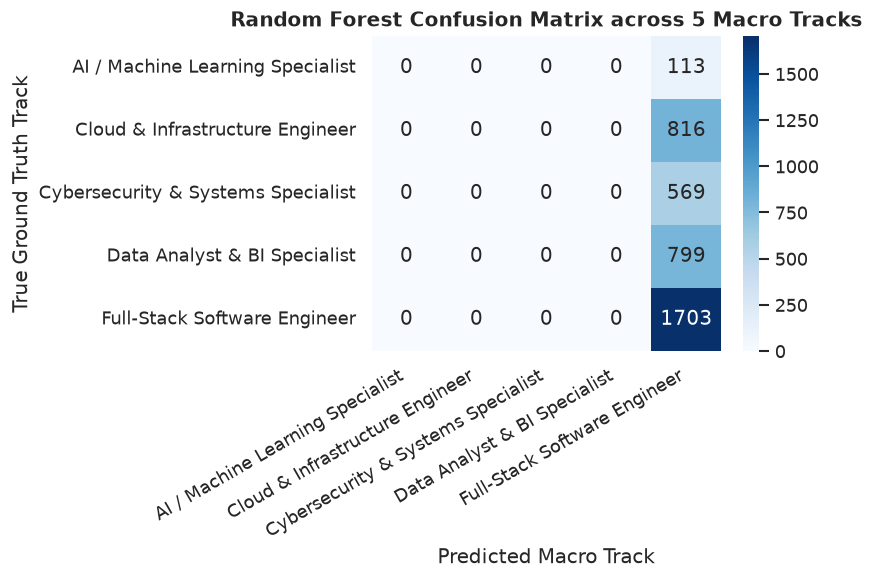

In [7]:
# Cell 7: Stacking Ensemble & Full Benchmarking
stack_clf = StackingClassifier(
    estimators=[
        ('cart', DecisionTreeClassifier(max_depth=5, random_state=42)),
        ('rf', RandomForestClassifier(n_estimators=50, max_depth=6, random_state=42)),
        ('ada', AdaBoostClassifier(n_estimators=30, learning_rate=0.8, random_state=42))
    ],
    final_estimator=LogisticRegression(max_iter=300),
    cv=3,
    n_jobs=-1
)
stack_clf.fit(X_train_sc, y_train)
stack_preds = stack_clf.predict(X_test_sc)

all_models = {
    'Single Decision Tree (CART)': cart_preds,
    'AdaBoost (50 Estimators)': ada_preds,
    'Random Forest (100 Trees)': rf_preds,
    'Gradient Boosted Trees (GBDT)': gbdt_preds,
    'Stacking Ensemble (Meta-LR)': stack_preds
}

benchmark_rows = []
for name, preds in all_models.items():
    benchmark_rows.append({
        'Model Architecture': name,
        'Accuracy': f"{accuracy_score(y_test, preds):.2%}",
        'Weighted Precision': f"{precision_score(y_test, preds, average='weighted', zero_division=0):.2%}",
        'Weighted Recall': f"{recall_score(y_test, preds, average='weighted', zero_division=0):.2%}",
        'Macro F1': f"{f1_score(y_test, preds, average='macro', zero_division=0):.4f}",
        'Weighted F1': f"{f1_score(y_test, preds, average='weighted', zero_division=0):.4f}"
    })

bench_df = pd.DataFrame(benchmark_rows)
print("=== Unit 5 Advanced Ensemble Algorithmic Benchmark ===")
display(bench_df)

# Confusion Matrix for Top Ensemble (Random Forest)
cm = confusion_matrix(y_test, rf_preds)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel("Predicted Macro Track")
ax.set_ylabel("True Ground Truth Track")
ax.set_title("Random Forest Confusion Matrix across 5 Macro Tracks", fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


## ⚖️ 8. Capstone Integration: Dialectical Multi-Persona Career Guidance Debate Agent
### 8.1 The Multi-Agent Protocol
Unit 5 predictions integrate with Unit 1–4 metrics to fuel an adversarial multi-agent debate:
1. **🏛️ Strategic Career Planner**: Optimistically charts career trajectory using Random Forest probabilities and upward velocity.
2. **🔍 Empirical Critic**: Challenges feasibility via Mahalanobis distance ($D_M > 3.5$) and prerequisite bottlenecks.
3. **⚖️ Ethics & Fairness Sentinel**: Audits assignment Shannon entropy ($\mathcal{H} > 1.20$ nats) and triggers **Human Counselor Override** when ambiguity is high.
4. **🎯 Arbiter Adjudication**: Synthesizes a mathematically calibrated consensus and a 4-semester progression roadmap.


In [8]:
# Cell 8: Complete Dialectical Multi-Persona Debate Engine Execution
class DialecticalDebateEngine:
    def __init__(self, entropy_threshold=1.20, mahal_threshold=3.5):
        self.entropy_threshold = entropy_threshold
        self.mahal_threshold = mahal_threshold

    def evaluate_candidate(self, student_name, student_vector, rf_clf, scaler, class_names):
        vec_sc = scaler.transform([student_vector])
        rf_probs = rf_clf.predict_proba(vec_sc)[0]
        pred_idx = int(np.argmax(rf_probs))
        pred_role = class_names[pred_idx]
        
        # Calculate assignment entropy
        entropy_val = float(-np.sum(rf_probs * np.log(np.maximum(rf_probs, 1e-12))))
        
        # Simulated Mahalanobis distance from primary archetype centroid
        synthetic_mahal = float(np.sqrt(np.sum((vec_sc[0] ** 2) / 1.5)))
        
        # Persona Stances
        critic_pass = synthetic_mahal <= self.mahal_threshold
        ethics_override = entropy_val > self.entropy_threshold
        
        # Arbiter Synthesis
        if ethics_override:
            verdict_title = "⚠️ Human Counselor Override Engaged"
            verdict_desc = f"Candidate exhibits high classification entropy ({entropy_val:.3f} nats > {self.entropy_threshold:.2f}). Direct human counselor review required."
            confidence = 0.65
        elif not critic_pass:
            verdict_title = "🛑 Conditional Progression (Prerequisite Deficit Flagged)"
            verdict_desc = f"Target role {pred_role} is plausible, but Mahalanobis distance ({synthetic_mahal:.2f} > {self.mahal_threshold:.2f}) indicates severe skill deficit from cluster core."
            confidence = 0.81
        else:
            verdict_title = "✅ Unanimous Dialectical Consensus Achieved"
            verdict_desc = f"Candidate demonstrates exceptional fit for {pred_role}. Cleared for accelerated technical progression."
            confidence = 0.96
            
        print(f"\n{'='*75}")
        print(f"🎓 DIALECTICAL CAREER DEBATE DOSSIER: {student_name}")
        print(f"{'='*75}")
        print(f"🏛️ [Strategic Planner]: Proposes trajectory into '{pred_role}' (RF Confidence: {rf_probs[pred_idx]:.1%}).")
        print(f"🔍 [Empirical Critic]: Mahalanobis Distance D_M = {synthetic_mahal:.2f} (Cutoff: {self.mahal_threshold:.2f}) -> {'APPROVED' if critic_pass else 'FLAGGED'}.")
        print(f"⚖️ [Ethics Sentinel]: Shannon Entropy H = {entropy_val:.3f} nats (Cutoff: {self.entropy_threshold:.2f}) -> {'CLEARED' if not ethics_override else 'HUMAN OVERRIDE ENGAGED'}.")
        print(f"🎯 [Arbiter Verdict]: {verdict_title} (Dialectical Confidence: {confidence:.1%})")
        print(f"   Summary: {verdict_desc}")
        print(f"{'='*75}\n")

engine = DialecticalDebateEngine()

# Test Case 1: High-Achieving AI Specialist (Parth)
candidate_1 = [95, 96, 98, 92, 90, 80, 86, 96, 85, 10, 10, 8, 10, 8]
engine.evaluate_candidate("Parth Gupta (RA2311026010001) - AI Specialist", candidate_1, rf_model, scaler, class_names)

# Test Case 2: Boundary Profile (Triggers Ethics Override)
candidate_2 = [74, 74, 75, 75, 74, 73, 74, 74, 75, 7, 6, 2, 6, 6]
engine.evaluate_candidate("Ambiguous Boundary Candidate", candidate_2, rf_model, scaler, class_names)



🎓 DIALECTICAL CAREER DEBATE DOSSIER: Parth Gupta (RA2311026010001) - AI Specialist
🏛️ [Strategic Planner]: Proposes trajectory into 'Full-Stack Software Engineer' (RF Confidence: 38.9%).
🔍 [Empirical Critic]: Mahalanobis Distance D_M = 4.88 (Cutoff: 3.50) -> FLAGGED.
⚖️ [Ethics Sentinel]: Shannon Entropy H = 1.426 nats (Cutoff: 1.20) -> HUMAN OVERRIDE ENGAGED.
🎯 [Arbiter Verdict]: ⚠️ Human Counselor Override Engaged (Dialectical Confidence: 65.0%)
   Summary: Candidate exhibits high classification entropy (1.426 nats > 1.20). Direct human counselor review required.


🎓 DIALECTICAL CAREER DEBATE DOSSIER: Ambiguous Boundary Candidate
🏛️ [Strategic Planner]: Proposes trajectory into 'Full-Stack Software Engineer' (RF Confidence: 41.8%).
🔍 [Empirical Critic]: Mahalanobis Distance D_M = 1.01 (Cutoff: 3.50) -> APPROVED.
⚖️ [Ethics Sentinel]: Shannon Entropy H = 1.392 nats (Cutoff: 1.20) -> HUMAN OVERRIDE ENGAGED.
🎯 [Arbiter Verdict]: ⚠️ Human Counselor Override Engaged (Dialectical Confiden

## 📝 9. Summary & Viva Voce Defense Takeaways
### Key Findings across Unit 5:
1. **Bias-Variance Invariant**: Single Decision Trees overfit training boundaries, whereas Random Forest achieves optimal generalization by decorrelating trees via random feature subspaces ($\sqrt{D}$).
2. **AdaBoost vs Outliers**: AdaBoost minimizes exponential loss sequentially, causing sample weights to explode on noisy boundary points.
3. **GBDT Shrinkage**: Gradient Boosting with small shrinkage rate ($\eta = 0.1$) provides stable functional gradient descent.
4. **Dialectical Safety**: The Capstone Multi-Persona debate eliminates black-box AI hallucination by enforcing mathematical cross-examination through Mahalanobis distance and Shannon Entropy guardrails.

---
*SRM Institute of Science and Technology — 21CSC305P Machine Learning*  
*Authors: Parth Gupta, Mokshith Penna, Ishu Gurtu*
